<a href="https://colab.research.google.com/github/priyankasaklani10/-Fashion-MNIST/blob/main/malwaredetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
import zipfile

with zipfile.ZipFile("/content/archive (23).zip", "r") as zip_ref:
    # List all files inside the zip
    print(zip_ref.namelist())

    # Extract everything to a folder
    zip_ref.extractall("target_folder")

['dataset-features-categories.csv', 'drebin-215-dataset-5560malware-9476-benign.csv']


In [ ]:
#data preprocessing: replacing ? with 0
df['TelephonyManager.getSimCountryIso'] = df['TelephonyManager.getSimCountryIso'].replace('?', '0')
df['TelephonyManager.getSimCountryIso'] = pd.to_numeric(df['TelephonyManager.getSimCountryIso'])

In [ ]:
df['class'] = df['class'].map({'S': 1, 'B': 0})

In [ ]:
# Define Features (X) and Target (y)
X = df.drop(columns=['class'])
y = df['class']

In [ ]:
# Split the data into Training and Testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# 4. Initialize the Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Support Vector Machine (SVM)": SVC(kernel='linear'),
}

In [ ]:
# 5. Train and Evaluate each model
import pandas as pd

# The error occurred because df['class'] was corrupted with NaNs from multiple map() runs.
# We reload the data and re-preprocess to ensure clean inputs.
file_path = 'target_folder/drebin-215-dataset-5560malware-9476-benign.csv'
df = pd.read_csv(file_path)

# Re-apply mapping and preprocessing
df['class'] = df['class'].map({'S': 1, 'B': 0})
df['TelephonyManager.getSimCountryIso'] = df['TelephonyManager.getSimCountryIso'].replace('?', '0')
df['TelephonyManager.getSimCountryIso'] = pd.to_numeric(df['TelephonyManager.getSimCountryIso'])

# Refresh X, y and split to ensure we don't have NaNs
X = df.drop(columns=['class'])
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for name, model in models.items():
    print(f"\n{'='*20} {name} {'='*20}")

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    # Calculate and Print Metrics
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {accuracy:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Benign', 'Malware']))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

/tmp/ipython-input-4281684012.py:7: DtypeWarning: Columns (92) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)



==================== Logistic Regression ====================
Accuracy: 0.9747

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98      1863
     Malware       0.98      0.96      0.97      1145

    accuracy                           0.97      3008
   macro avg       0.97      0.97      0.97      3008
weighted avg       0.97      0.97      0.97      3008

Confusion Matrix:
[[1836   27]
 [  49 1096]]

==================== Support Vector Machine (SVM) ====================
Accuracy: 0.9774

Classification Report:
              precision    recall  f1-score   support

      Benign       0.98      0.99      0.98      1863
     Malware       0.98      0.96      0.97      1145

    accuracy                           0.98      3008
   macro avg       0.98      0.97      0.98      3008
weighted avg       0.98      0.98      0.98      3008

Confusion Matrix:
[[1836   27]
 [  41 1104]]


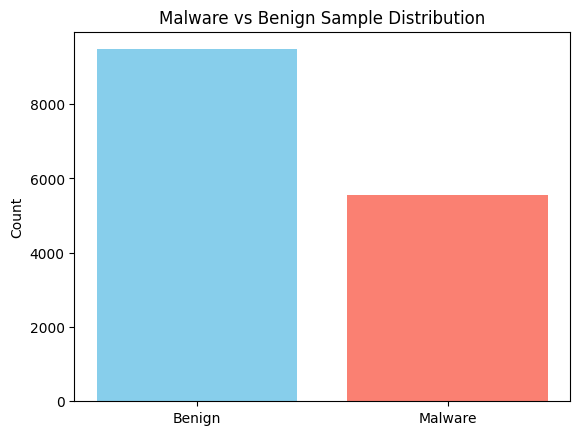

In [ ]:
import matplotlib.pyplot as plt

# Calculate counts from the 'class' column
# Note: 'B' (Benign) was mapped to 0 and 'S' (Malware) was mapped to 1
class_counts = df['class'].value_counts()

# Plotting
labels = ['Benign', 'Malware']
counts = [class_counts[0], class_counts[1]]

plt.bar(labels, counts, color=['skyblue', 'salmon'])
plt.title('Malware vs Benign Sample Distribution')
plt.ylabel('Count')
plt.show()